# Option Pricing Agent: pipeline walkthrough

This notebook follows one NIFTY option chain through everything built so far, from raw market data to
implied volatilities and Greeks. Each step shows **what goes in, what comes out, and why it is done that way**.

| Step | What it does | Module |
| --- | --- | --- |
| 1. Market data | Option chain, index spot and futures from Upstox | `optlib.data.upstox` |
| 2. Discount curve | FBIL MIBOR-OIS rates bootstrapped into discount factors | `optlib.curves` |
| 3. Forward | The market's forward for the expiry, from put-call parity | `optlib.forwards` |
| 4. Chain QA | Which quotes are fit to use, and why the rest are dropped | `optlib.qa` |
| 5. Implied vols | Bid, mid and ask vols for the quotes that passed QA: the smile | `optlib.slices`, `optlib.iv` |
| 6. Pricing and Greeks | Black-76 price and Greeks off that forward, rate and vol | `optlib.black` |
| 7. Validation | The in-house library checked against QuantLib | `optlib.benchmark` |

Next to build: the SVI surface fit, the validator agent, the API and the dashboard.

**Data.** By default the notebook replays the live snapshot saved on **23 Oct 2026 at 11:03 IST** (NIFTY,
27 Oct expiry) and the FBIL rates of that week, so every number below is reproducible. Set `LIVE = True`
to pull fresh data instead (needs the Upstox token in `.env` and market hours for live bids and asks).

In [1]:
LIVE = False          # True: fresh Upstox + FBIL data; False: the recorded 23 Oct 2026 snapshot
UNDERLYING = "NIFTY"

import math
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from optlib import black76_greeks, black76_price, implied_vol_black76
from optlib.curves import bootstrap_mibor_ois
from optlib.data.fbil import FBILClient
from optlib.data.models import nse_expiry_instant
from optlib.data.replay import fbil_from_files, snapshot_source
from optlib.data.upstox import UpstoxSource
from optlib.slices import build_vol_slice

FIX = ROOT / "tests" / "fixtures"
CALL, PUT, GREY, ACCENT, GOOD = "#2563eb", "#ea580c", "#6b7280", "#7c3aed", "#16a34a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "axes.titleweight": "bold"})

## 1. Market data

`UpstoxSource` returns vendor-neutral objects (`OptionChain`, `FutureQuote`), so everything downstream would
work unchanged on Bloomberg data later. Expiries come from the exchange's own contract list, which already
includes holiday shifts (the November monthly expires on **Monday 23 Nov** because Tuesday 24 Nov is a holiday).

In [2]:
if LIVE:
    src = UpstoxSource.from_env([ROOT], cache_dir=ROOT / "data" / "cache")
    expiry = src.expiries(UNDERLYING)[0]
    fbil = FBILClient(cache_dir=ROOT / "data" / "cache")
else:
    src, meta = snapshot_source(FIX / "upstox_live_nifty_20261023_full.json", FIX / "upstox_instruments_sample.json")
    expiry = meta["expiry"]
    fbil = fbil_from_files(FIX / "fbil_miborois_20261001_20261023.json", FIX / "fbil_ovnmibor_20261001_20261023.json")

chain = src.option_chain(UNDERLYING, expiry)
futures = src.futures(UNDERLYING)
spot = chain.spot

print(f"Snapshot   {chain.as_of:%a %d %b %Y %H:%M} IST")
print(f"Spot       {spot:,.2f}")
print(f"Expiry     {chain.expiry:%a %d %b %Y}, 15:30 IST  ->  T = {chain.time_to_expiry() * 365:.2f} days")
print(f"Chain      {len(chain.strikes)} strikes ({chain.strikes[0]:,.0f} to {chain.strikes[-1]:,.0f}), "
      f"{len(chain.quotes)} options")
print("Expiries  ", ", ".join(f"{d:%d %b}" for d in src.expiries(UNDERLYING)[:6]))
pd.DataFrame([{"expiry": f.expiry, "bid": f.bid, "ask": f.ask, "last": f.last, "open interest": f.oi}
              for f in futures]).set_index("expiry").style.format(
    {"bid": "{:,.2f}", "ask": "{:,.2f}", "last": "{:,.2f}", "open interest": "{:,.0f}"})

Snapshot   Fri 23 Oct 2026 11:03 IST
Spot       22,461.10
Expiry     Tue 27 Oct 2026, 15:30 IST  ->  T = 4.19 days
Chain      144 strikes (20,050 to 27,200), 288 options
Expiries   27 Oct, 23 Nov, 29 Dec, 30 Mar, 29 Jun, 28 Sep


,bid,ask,last,open interest
expiry,,,,
2026-10-27,"22,515.60","22,521.50","22,515.60","13,632,840"
2026-11-23,"22,601.00","22,604.90","22,601.00","6,758,115"
2026-12-29,"22,731.60","22,744.00","22,732.30","778,765"


**Reading the chain.** Left: option prices by strike (log scale). Out-of-the-money options are cheap and
in-the-money options are worth roughly their intrinsic value. Right: open interest, i.e. where positions sit.
Large call open interest above spot and put open interest below it often act as resistance and support
into expiry.

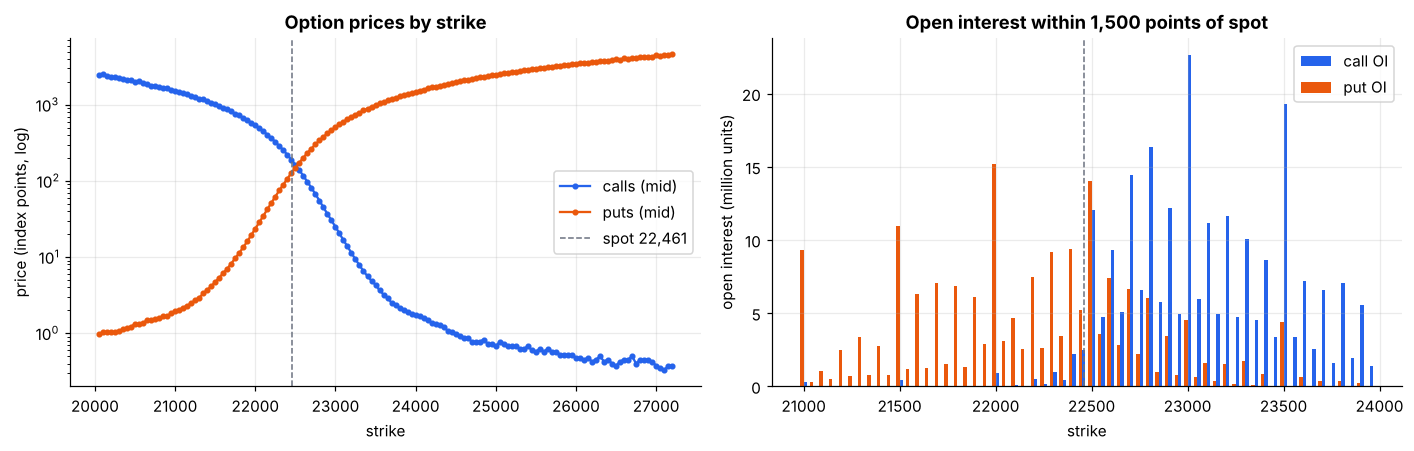

In [3]:
df_chain = chain.to_frame()
df_chain["mid"] = 0.5 * (df_chain.bid + df_chain.ask)
calls, puts = df_chain[df_chain.option_type == "call"], df_chain[df_chain.option_type == "put"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
a1.semilogy(calls.strike, calls.mid, ".-", color=CALL, label="calls (mid)")
a1.semilogy(puts.strike, puts.mid, ".-", color=PUT, label="puts (mid)")
a1.axvline(spot, color=GREY, ls="--", lw=1, label=f"spot {spot:,.0f}")
a1.set(title="Option prices by strike", xlabel="strike", ylabel="price (index points, log)")
a1.legend()
near = df_chain[(df_chain.strike - spot).abs() <= 1500]
w = 18
a2.bar(near[near.option_type == "call"].strike + w / 2, near[near.option_type == "call"].oi / 1e6, w, color=CALL, label="call OI")
a2.bar(near[near.option_type == "put"].strike - w / 2, near[near.option_type == "put"].oi / 1e6, w, color=PUT, label="put OI")
a2.axvline(spot, color=GREY, ls="--", lw=1)
a2.set(title="Open interest within 1,500 points of spot", xlabel="strike", ylabel="open interest (million units)")
a2.legend()
plt.tight_layout()

## 2. Discount curve (FBIL MIBOR-OIS)

FBIL publishes MIBOR-OIS fixed rates for 1M to 5Y. We bootstrap them into discount factors using the market
conventions: a single payment up to 1 year, semi-annual payments beyond, Actual/365, starting T+1.
The curve reprices every input rate exactly (checked in the tests).

FBIL's free public data runs several business days behind, so the curve records **how old its inputs are**
and QA warns beyond 10 days. For options this matters little: the rate only discounts the payoff, because
the forward comes from option prices (next step).

*Why the line sits below the dots:* FBIL quotes par rates with simple interest (one payment up to 1 year) or
semi-annual payments beyond. The line is the continuously compounded zero rate, which is lower for the same
discount factor. The dip at the very start is real: overnight MIBOR (5.87%) was above the 1-month rate (5.70%).

FBIL fixing 15 Oct 2026  (8 days before the pricing date)
Rate for this option (continuous, to expiry): 5.797%


,maturity,discount factor,zero rate
O/N,2026-10-26,0.999518,5.869%
1M,2026-11-26,0.994702,5.702%
2M,2026-12-28,0.989678,5.738%
3M,2027-01-26,0.984872,5.857%
6M,2027-04-26,0.969732,6.064%
9M,2027-07-26,0.954539,6.153%
1Y,2027-10-26,0.939043,6.238%
2Y,2028-10-26,0.877634,6.491%
3Y,2029-10-26,0.820747,6.561%
4Y,2030-10-28,0.766777,6.612%


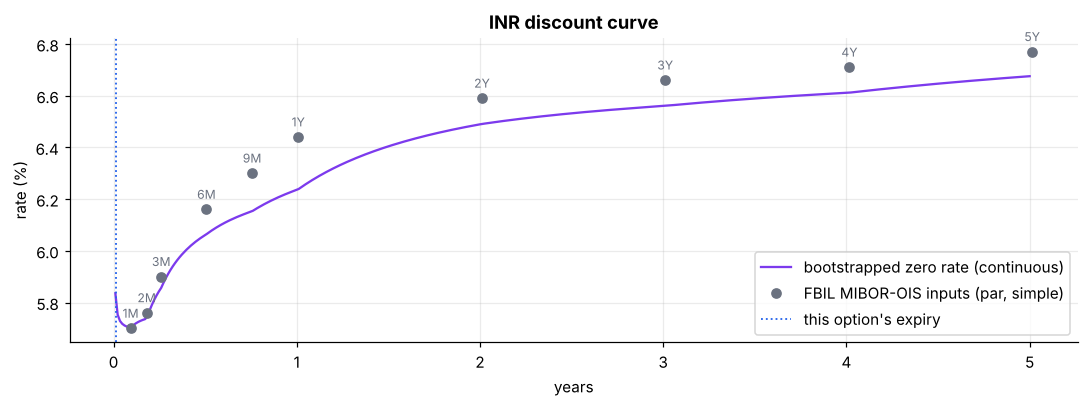

In [4]:
ois = fbil.ois_quotes(chain.as_of.date())
curve = bootstrap_mibor_ois(ois, chain.as_of.date())
expiry_dt = nse_expiry_instant(chain.expiry)
r = curve.rate_for_option(chain.as_of, expiry_dt)

print(f"FBIL fixing {ois.fixing_date:%d %b %Y}  ({curve.age_days()} days before the pricing date)")
print(f"Rate for this option (continuous, to expiry): {r:.3%}")

tenor_t = {t: curve.time(d) for t, (d, _) in curve.pillars.items() if t != "O/N"}
ts = np.linspace(0.01, 5.0, 400)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ts, [curve.zero_rate(t) * 100 for t in ts], color=ACCENT, label="bootstrapped zero rate (continuous)")
ax.plot(list(tenor_t.values()), [ois.tenors[t] for t in tenor_t], "o", color=GREY, label="FBIL MIBOR-OIS inputs (par, simple)")
for t, x in tenor_t.items():
    ax.annotate(t, (x, ois.tenors[t]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color=GREY)
ax.axvline(chain.time_to_expiry(), color=CALL, ls=":", lw=1.2, label="this option's expiry")
ax.set(title="INR discount curve", xlabel="years", ylabel="rate (%)")
ax.legend(loc="lower right")
plt.tight_layout()
pd.DataFrame({"maturity": [d for d, _ in curve.pillars.values()],
              "discount factor": [df for _, df in curve.pillars.values()],
              "zero rate": [curve.zero_rate(curve.time(d)) for d, _ in curve.pillars.values()]},
             index=list(curve.pillars)).style.format({"discount factor": "{:.6f}", "zero rate": "{:.3%}"})

## 3. The forward: why it comes from options, not from spot

Black-76 prices an option off the **forward** for its expiry. A tempting shortcut is spot × e^(rT), but that
ignores dividends, borrow and the futures basis. Put-call parity gives the market's own forward at every strike:

$$F_K = K + \frac{C_K - P_K}{DF}$$

Each dot below is one strike's estimate. They cluster tightly, the robust median (purple) sits on the
same-expiry future, and spot × carry (grey) is well below both.

Parity forward  22,513.88  (from 11 strikes; estimates span 2.46 points)
Future          22,518.55  gap -0.021% -> PASS (spec: warn above 0.05%, fail above 0.20%)
Spot x carry    22,476.03  (-0.168%)


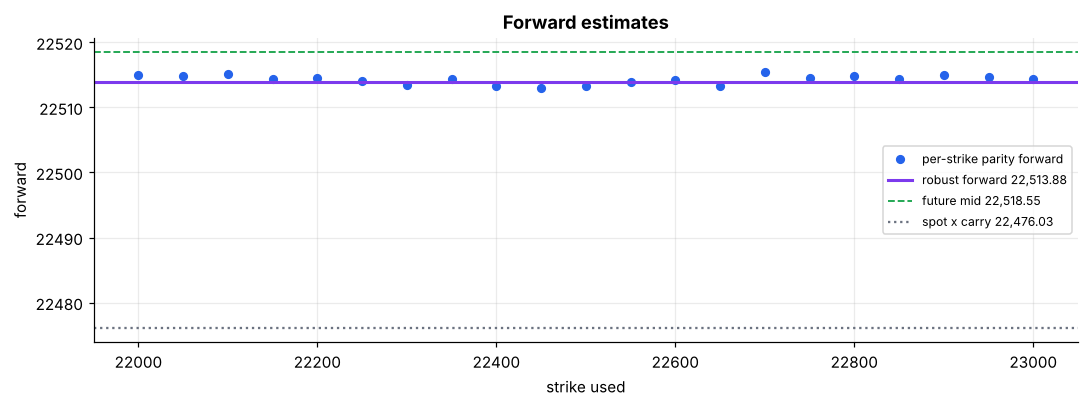

In [5]:
s = build_vol_slice(chain, curve, future_price=futures[0].mid if futures and futures[0].expiry == chain.expiry else None)
F, T, DF = s.forward.forward, s.time_to_expiry, s.discount_factor
naive = spot * math.exp(r * T)

near = sorted(chain.strikes, key=lambda k: abs(k - F))[:21]
pts = sorted((k, k + (chain.quote(k, "call").mid - chain.quote(k, "put").mid) / DF) for k in near
             if chain.quote(k, "call").two_sided and chain.quote(k, "put").two_sided)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot([k for k, _ in pts], [f for _, f in pts], "o", color=CALL, ms=5, label="per-strike parity forward")
ax.axhline(F, color=ACCENT, lw=2, label=f"robust forward {F:,.2f}")
if s.forward_check:
    ax.axhline(s.forward_check.future, color=GOOD, ls="--", lw=1.2, label=f"future mid {s.forward_check.future:,.2f}")
ax.axhline(naive, color=GREY, ls=":", lw=1.5, label=f"spot x carry {naive:,.2f}")
ax.set(title="Forward estimates", xlabel="strike used", ylabel="forward")
ax.legend(loc="center right", fontsize=8)
plt.tight_layout()

print(f"Parity forward  {F:,.2f}  (from {s.forward.n_strikes} strikes; estimates span {s.forward.dispersion:.2f} points)")
if s.forward_check:
    c = s.forward_check
    print(f"Future          {c.future:,.2f}  gap {c.gap:+.3%} -> {c.verdict} (spec: warn above 0.05%, fail above 0.20%)")
print(f"Spot x carry    {naive:,.2f}  ({(naive - F) / F:+.3%})")

**What the wrong forward does.** With the parity forward, a call and a put at the same strike imply the same
volatility, as they must. With spot × carry, they split apart by several vol points: every price and Greek built
on them would be off.

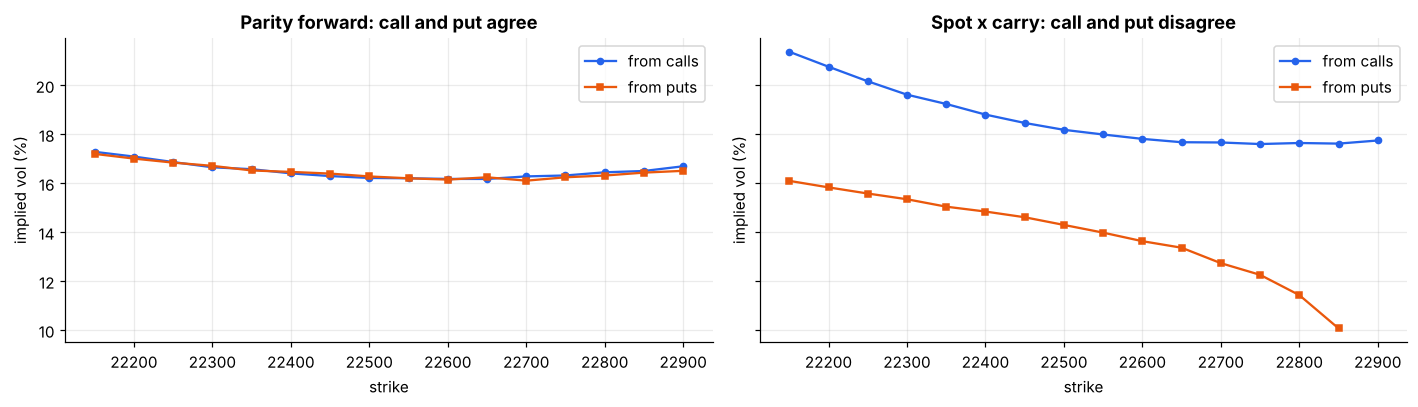

In [6]:
ks = [k for k in chain.strikes if abs(k - F) <= 400]
def vols(fwd, kind):
    return [implied_vol_black76(chain.quote(k, kind).mid, fwd, k, T, r, kind) * 100 for k in ks]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, fwd, title in ((a1, F, "Parity forward: call and put agree"), (a2, naive, "Spot x carry: call and put disagree")):
    ax.plot(ks, vols(fwd, "call"), "o-", color=CALL, ms=4, label="from calls")
    ax.plot(ks, vols(fwd, "put"), "s-", color=PUT, ms=4, label="from puts")
    ax.set(title=title, xlabel="strike", ylabel="implied vol (%)")
    ax.legend()
plt.tight_layout()

## 4. Chain QA: which quotes we trust

Every quote is kept or dropped with a named reason, so a quant (or the validator agent) can see exactly what fed
the smile. We keep only the **out-of-the-money side** of each strike: puts below the forward, calls above.
In-the-money options are mostly intrinsic value, with wide and often stale quotes, and carry little volatility
information.

| Rule | Drops a quote when |
| --- | --- |
| `missing_bid_or_ask` | there is no live two-sided market |
| `crossed_or_locked` | ask ≤ bid |
| `itm_side` | it is the in-the-money side of its strike |
| `below_intrinsic` | the mid is below discounted intrinsic value |
| `price_below_min` | the mid is under ₹0.50, so the tick size dominates |
| `wide_spread` | the spread exceeds 10% of mid (and 2 ticks) |
| `outside_moneyness` | the strike is more than 25% (log) from the forward |

Quotes with no trades today are kept but flagged, and get half weight in the fit. Static arbitrage is checked on
what remains: tiny violations (within a tick, or too small to trade after costs) warn, large ones fail the chain.

In the chart a quote that fails several rules is coloured by its first, so the counts in the legend can be lower
than in the summary above. On this snapshot QA found one real but tiny arbitrage: the 25,050 call bid ₹0.75
while the 25,000 call offered at ₹0.70. That is ₹0.05 per unit, too small to trade after costs, so it warns.

QA 2026-10-27: kept 114 of 288 quotes (WARN)
  dropped: itm_side 144, wide_spread 13, price_below_min 23
  flags: no_volume_today 62
  arbitrage: monotonicity at 25000, 25050 (0.05 pts)
  WARN 1 static-arbitrage violation(s), largest 0.05 pts (fail above 0.5 pts)


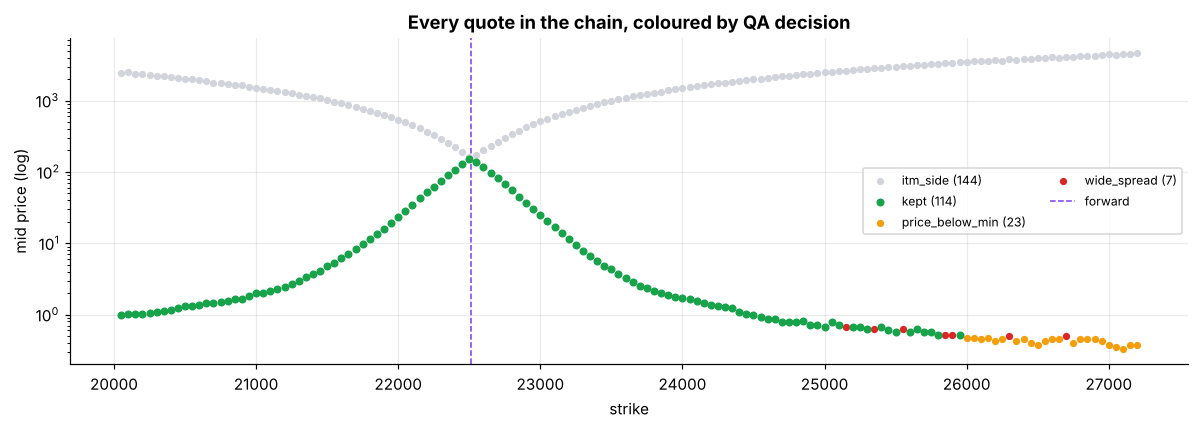

In [7]:
print(s.qa.summary())

rows = []
for d in s.qa.decisions:
    q = d.quote
    rows.append({"strike": q.strike, "type": q.option_type, "mid": q.mid,
                 "status": "kept" if d.keep else d.reasons[0]})
qa_df = pd.DataFrame(rows)
colors = {"kept": GOOD, "itm_side": "#d1d5db", "wide_spread": "#dc2626", "price_below_min": "#f59e0b",
          "missing_bid_or_ask": "#111827", "crossed_or_locked": "#be185d", "below_intrinsic": "#9333ea",
          "outside_moneyness": "#0891b2"}
fig, ax = plt.subplots(figsize=(11, 4))
for status, grp in qa_df.groupby("status"):
    ax.scatter(grp.strike, grp.mid, s=14 if status != "kept" else 18, color=colors.get(status, GREY),
               label=f"{status} ({len(grp)})", zorder=3 if status == "kept" else 2)
ax.set_yscale("log")
ax.axvline(F, color=ACCENT, ls="--", lw=1, label="forward")
ax.set(title="Every quote in the chain, coloured by QA decision", xlabel="strike", ylabel="mid price (log)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()

## 5. The smile

For each kept quote we solve for the Black-76 volatility at the bid, the mid and the ask. The shaded band is
the bid-ask range in vol terms: narrow near the money where the market is liquid, wider in the wings.
Near the money the band is only about 0.03 vol points wide, so thin it is hard to see: NIFTY weeklies are very
liquid. Upstox's own IVs (dots) match closely in the wings. Near the money they are about 0.3 points higher on
puts and lower on calls, the same pattern as the spot × carry chart above in milder form. That is consistent with
Upstox using a lower forward than the market's; their method is not published.

NIFTY's short-dated smile is typical of equity indices: puts (downside protection) are priced at higher vols
than calls, and both wings rise above the at-the-money level.

,type,bid,ask,iv_bid,iv_mid,iv_ask,vega
strike,,,,,,,
"22,250",put,62.20,62.40,16.83%,16.84%,16.86%,771.7
"22,300",put,75.10,75.30,16.70%,16.71%,16.72%,829.7
"22,350",put,89.55,89.75,16.51%,16.52%,16.54%,879.4
"22,400",put,107.30,107.55,16.45%,16.46%,16.48%,919.8
"22,450",put,127.35,127.65,16.38%,16.40%,16.41%,947.2
"22,500",put,149.50,149.65,16.27%,16.28%,16.29%,960.2
"22,550",call,138.35,138.60,16.19%,16.20%,16.22%,957.8
"22,600",call,116.40,116.65,16.16%,16.18%,16.19%,939.8
"22,650",call,97.15,97.40,16.16%,16.18%,16.19%,907.4


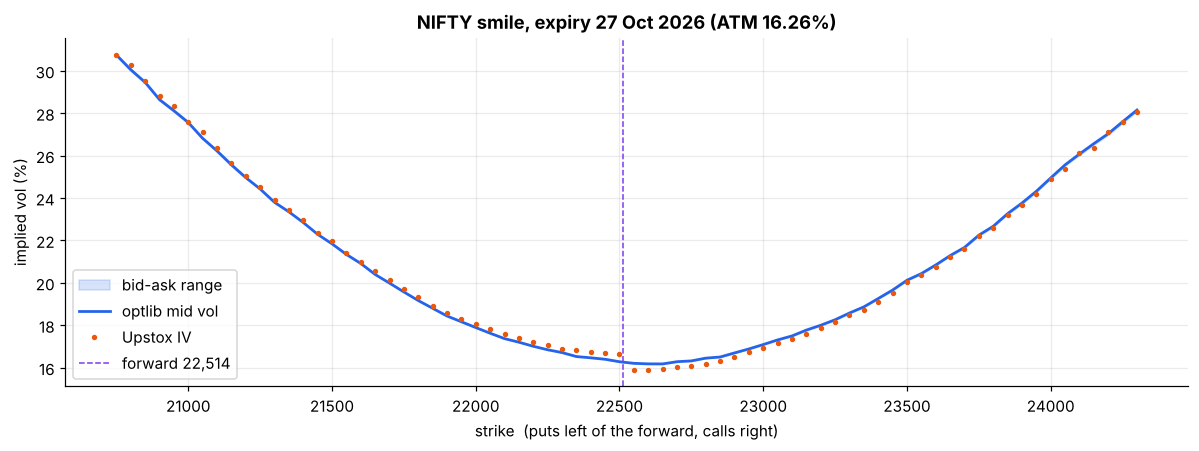

In [8]:
kmask = np.abs(s.strikes - F) <= 1800
x = s.strikes[kmask]
vendor = np.array([chain.quote(float(k), str(t)).vendor_iv for k, t in zip(s.strikes[kmask], s.option_types[kmask])])

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(x, s.iv_bid[kmask] * 100, s.iv_ask[kmask] * 100, color=CALL, alpha=0.18, label="bid-ask range")
ax.plot(x, s.iv_mid[kmask] * 100, "-", color=CALL, lw=1.8, label="optlib mid vol")
ax.plot(x, vendor, ".", color=PUT, ms=5, label="Upstox IV")
ax.axvline(F, color=ACCENT, ls="--", lw=1, label=f"forward {F:,.0f}")
ax.set(title=f"{UNDERLYING} smile, expiry {chain.expiry:%d %b %Y} (ATM {s.atm_vol():.2%})",
       xlabel="strike  (puts left of the forward, calls right)", ylabel="implied vol (%)")
ax.legend()
plt.tight_layout()

smile = pd.DataFrame(s.to_records()).set_index("strike")
smile.loc[(smile.index - F).__abs__() <= 300, ["type", "bid", "ask", "iv_bid", "iv_mid", "iv_ask", "vega"]].style.format(
    {"bid": "{:,.2f}", "ask": "{:,.2f}", "iv_bid": "{:.2%}", "iv_mid": "{:.2%}", "iv_ask": "{:.2%}", "vega": "{:,.1f}"}).format_index("{:,.0f}", axis=0)

## 6. Pricing and Greeks

With the forward, rate and each strike's market vol, `black76_greeks` returns the price and the full set of
Greeks. `reporting_units()` converts them to desk units: vega per vol point, theta per calendar day,
rho per basis point. Multiply by the lot size for per-lot figures.

In [9]:
LOT = src.instruments.lot_size(UNDERLYING)
k_atm = float(min(s.strikes, key=lambda k: abs(k - F)))
iv_atm = float(s.iv_mid[s.strikes == k_atm][0])
rows = {}
for kind in ("call", "put"):
    g = black76_greeks(F, k_atm, T, r, iv_atm, kind).reporting_units()
    rows[kind] = {name: float(v) for name, v in g.items()}
greeks = pd.DataFrame(rows)
greeks["call, per lot"] = greeks["call"] * LOT
print(f"Strike {k_atm:,.0f}, vol {iv_atm:.2%}, forward {F:,.2f}, rate {r:.3%}, T {T * 365:.2f} days, lot {LOT}")
greeks.style.format(lambda v: f"{v:,.2f}" if abs(v) >= 1 else f"{v:.6f}")

Strike 22,500, vol 16.28%, forward 22,513.88, rate 5.797%, T 4.19 days, lot 65


,call,put,"call, per lot"
price,163.44,149.58,"10,623.72"
delta,0.517237,-0.482098,33.62
gamma,0.001015,0.001015,0.065967
vega,9.60,9.60,624.13
theta,-18.65,-18.65,"-1,212.12"
rho,-0.000187,-0.000172,-0.012181
vanna,-0.000652,-0.000652,-0.042387
volga,0.000693,0.000693,0.045048
charm,0.001350,0.001192,0.087773
speed,-0.000000,-0.000000,-0.000010


**Greeks across strikes,** each strike at its own market vol (so the smile is respected). Gamma and theta peak at
the money and are large this close to expiry: with four days left, an at-the-money option loses value fast,
and its delta swings quickly as the index moves.

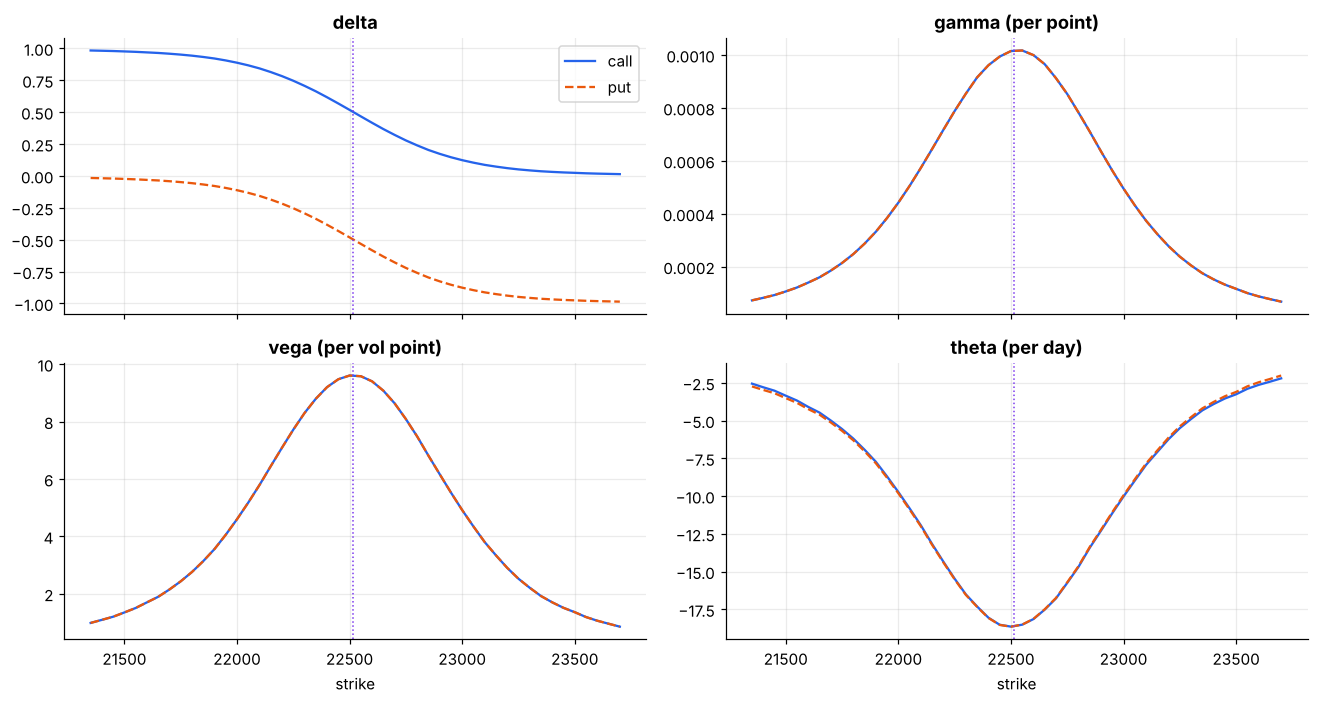

In [10]:
grid = np.array([k for k in s.strikes if abs(k - F) <= 1200])
gvol = np.array([s.iv_mid[s.strikes == k][0] for k in grid])
gc = black76_greeks(F, grid, T, r, gvol, "call").reporting_units()
gp = black76_greeks(F, grid, T, r, gvol, "put").reporting_units()

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, name, label in zip(axes.flat, ("delta", "gamma", "vega", "theta"),
                           ("delta", "gamma (per point)", "vega (per vol point)", "theta (per day)")):
    ax.plot(grid, gc[name], color=CALL, label="call")
    ax.plot(grid, gp[name], color=PUT, ls="--", label="put")
    ax.axvline(F, color=ACCENT, ls=":", lw=1)
    ax.set_title(label)
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("strike")
plt.tight_layout()

**How the at-the-money call responds to the index.** The curves show the option's value as the forward moves
±3%, today and with one and two days less to expiry (vol held fixed). The curvature is gamma; the drop between
the curves is theta.

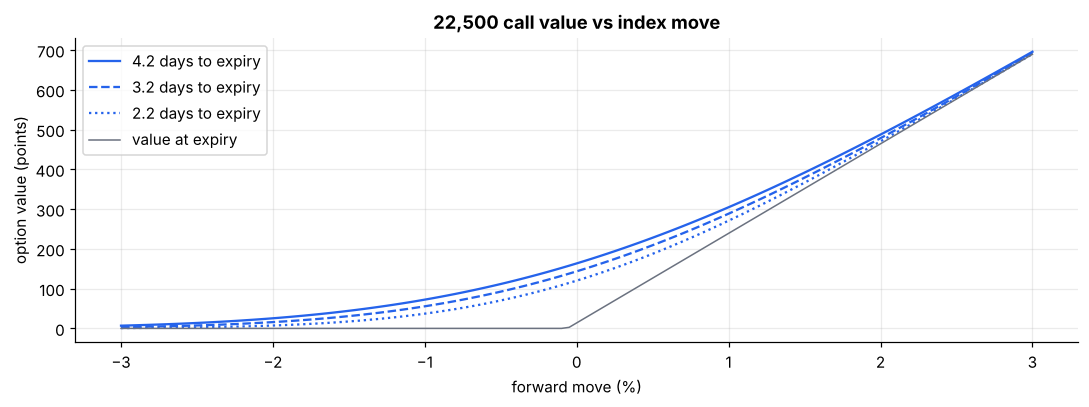

In [11]:
moves = np.linspace(-0.03, 0.03, 121)
fig, ax = plt.subplots(figsize=(10, 3.8))
for days_left, style in ((T * 365, "-"), (T * 365 - 1, "--"), (T * 365 - 2, ":")):
    ax.plot(moves * 100, black76_price(F * (1 + moves), k_atm, days_left / 365, r, iv_atm, "call"), style,
            color=CALL, label=f"{days_left:.1f} days to expiry")
ax.plot(moves * 100, np.maximum(F * (1 + moves) - k_atm, 0), color=GREY, lw=1, label="value at expiry")
ax.set(title=f"{k_atm:,.0f} call value vs index move", xlabel="forward move (%)", ylabel="option value (points)")
ax.legend()
plt.tight_layout()

## 7. Validation against QuantLib

The in-house library is checked against QuantLib on a grid of 1,260 options: 8,400 of 8,400 comparisons are
within the spec tolerances (price within max(₹0.01, 0.001%), Greeks within 0.01%). Here is the same check on
options from today's chain. QuantLib works on whole days, so T is rounded to days for the comparison.

In [12]:
try:
    from optlib.benchmark import quantlib_black76
except ImportError:
    quantlib_black76 = None

if quantlib_black76 is None:
    print("QuantLib not installed: pip install QuantLib")
else:
    T_days = round(T * 365) / 365
    out = []
    for k, kind in [(F - 500, "put"), (F - 100, "put"), (F + 100, "call"), (F + 500, "call")]:
        k = float(min(s.strikes, key=lambda x: abs(x - k)))
        vol = float(s.iv_mid[s.strikes == k][0])
        ours, ql = black76_greeks(F, k, T_days, r, vol, kind), quantlib_black76(F, k, T_days, r, vol, kind)
        out.append({"strike": k, "type": kind, "vol": vol, "optlib price": ours.price, "QuantLib price": ql.price,
                    "price diff": ours.price - ql.price, "delta diff": ours.delta - ql.delta,
                    "vega diff": ours.vega - ql.vega})
    display(pd.DataFrame(out).set_index("strike").style.format(
        {"vol": "{:.2%}", "optlib price": "{:,.4f}", "QuantLib price": "{:,.4f}",
         "price diff": "{:.1e}", "delta diff": "{:.1e}", "vega diff": "{:.1e}"}).format_index("{:,.0f}", axis=0))

,type,vol,optlib price,QuantLib price,price diff,delta diff,vega diff
strike,,,,,,,
"22,000",put,17.89%,21.8410,21.8410,3.6e-12,-2.5e-15,1.7e-13
"22,400",put,16.46%,104.0425,104.0425,3.3e-12,7.4e-15,-4.8e-12
"22,600",call,16.18%,113.1279,113.1279,-1.3e-12,-4.2e-15,-1.1e-12
"23,000",call,17.09%,23.1004,23.1004,5.8e-13,2.8e-16,1.1e-11


## What comes next

1. **SVI fit.** Fit a smooth, arbitrage-free curve through each expiry's bid-ask vols (weights from the QA step),
   then join the expiries into a surface. That lets us price any strike, not only listed ones.
2. **Validator agent.** Runs the checks seen here (parity, forward vs future, QA status, QuantLib cross-check) on
   every result before a quant sees it.
3. **API, agent and dashboard.** FastAPI endpoints for each tool, the orchestrator agent, and a Streamlit dashboard
   with book-level Greeks and a spot × vol scenario grid.

To rerun on fresh data: set `LIVE = True` in the first cell during market hours, then *Run All*.